# Preuve de concept : classer des produits Flipkart à partir de leur photo

**Baseline (projet 6) : réseaux convolutifs pré-entraînés sur ImageNet → nouvelle méthode : DINOv2 (Meta AI, 2023)**

Ce notebook est le livrable 2 du projet. Il contient, dans cet ordre :

1. le chargement et le contrôle des données ;
2. la préparation des images, identique pour tous les modèles ;
3. l'extraction des représentations d'images par les modèles gelés ;
4. l'entraînement et l'évaluation du même classifieur sur chaque représentation, en validation croisée ;
5. la comparaison statistique baseline / nouveau modèle ;
6. l'interprétabilité du nouveau modèle (importance locale et globale) ;
7. l'export du modèle final pour le dashboard.

## La question posée

Au projet 6, le meilleur résultat sur ces images était **82,4 % de bonnes réponses**, avec MobileNetV2
pré-entraîné sur ImageNet, gelé, surmonté d'une couche de classification. La veille a identifié
**DINOv2**, un Vision Transformer pré-entraîné *sans étiquettes* sur 142 millions d'images. La question :
**à protocole identique, est-ce que la représentation d'image de DINOv2 classe mieux les produits ?**

## Le principe de la comparaison

Pour que la comparaison soit honnête, **une seule chose change d'un modèle à l'autre : le réseau qui
transforme l'image en vecteur de nombres** (sa « représentation »). Tout le reste est identique :
les mêmes images, la même préparation, le même classifieur posé au-dessus (une régression logistique),
le même découpage en plis de validation, la même recherche de réglage.

On compare quatre réseaux, tous gelés (on ne modifie pas leurs poids) :

| Rôle | Réseau | Année | Paramètres utilisés | Pré-entraînement |
|---|---|---|---|---|
| Baseline 1 | MobileNetV2 | 2018 | 2,2 M | supervisé, ImageNet (1,3 M images étiquetées) |
| Baseline 2 | ResNet50 | 2015 | 23,5 M | supervisé, ImageNet |
| Nouveau, petit | DINOv2-reg ViT-S/14 | 2023 | 22,1 M | auto-supervisé, 142 M images sans étiquettes |
| Nouveau, base | DINOv2-reg ViT-B/14 | 2023 | 86,6 M | auto-supervisé, 142 M images sans étiquettes |

Les paramètres sont ceux réellement utilisés, mesurés en section 3 : pour MobileNetV2 et ResNet50, on
retire la couche de classification d'ImageNet (1 000 catégories) qui ne sert pas ici. Avec elle, ils
comptent 3,5 M et 25,6 M de paramètres, les chiffres habituellement cités.

MobileNetV2 est la baseline du projet 6. ResNet50 est ajouté pour une raison précise : il a à peu près
la taille de DINOv2-reg ViT-S/14. La comparaison des deux pose la question : le gain vient-il de la
méthode, ou simplement d'un modèle plus gros ? La section 5 y répond avec un test statistique.

**Code réutilisé** : le chargement du jeu Flipkart reprend mon notebook du projet 6 ; l'extraction des
représentations DINOv2 suit l'exemple de la fiche Hugging Face `facebook/dinov2-with-registers-base`.

## 0. L'environnement

In [1]:
import json
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps

import torch
import torchvision
import transformers
import sklearn
from torchvision import models as tv_models
from transformers import AutoModel

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report)
from statsmodels.stats.contingency_tables import mcnemar

# Certaines photos du jeu dépassent 90 millions de pixels : Pillow refuse de
# les ouvrir par défaut, par sécurité. Les fichiers viennent d'une source
# connue, on lève donc cette limite.
Image.MAX_IMAGE_PIXELS = None

GRAINE = 42
np.random.seed(GRAINE)

# Nombre de processus lancés en parallèle par scikit-learn pour la recherche du réglage C.
# Pas plus de 4 : avec tous les cœurs (16 processus sur ce portable), la machine devient
# inutilisable pendant le calcul, pour un gain de temps faible sur un si petit jeu de données.
N_PROCESSUS = 4
torch.manual_seed(GRAINE)

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DOSSIER_DONNEES = RACINE / "data" / "raw" / "Flipkart"
DOSSIER_IMAGES = DOSSIER_DONNEES / "Images"
DOSSIER_TRAVAIL = RACINE / "data" / "processed"
DOSSIER_FIGURES = RACINE / "docs" / "figures"
DOSSIER_MODELE = RACINE / "dashboard" / "modele"
for dossier in (DOSSIER_TRAVAIL, DOSSIER_FIGURES, DOSSIER_MODELE):
    dossier.mkdir(parents=True, exist_ok=True)

# Le calcul tourne sur carte graphique si elle existe, sinon sur processeur.
APPAREIL = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(max(1, torch.get_num_threads()))

print(f"Python {platform.python_version()} | torch {torch.__version__} | "
      f"torchvision {torchvision.__version__} | transformers {transformers.__version__} | "
      f"scikit-learn {sklearn.__version__}")
print("Calcul sur :", APPAREIL, "|", platform.processor())

Python 3.13.1 | torch 2.14.1+cpu | torchvision 0.29.1+cpu | transformers 5.18.0 | scikit-learn 1.9.1
Calcul sur : cpu | Intel64 Family 6 Model 186 Stepping 2, GenuineIntel


## 1. Les données

Le fichier CSV décrit les 1 050 produits. La catégorie à prédire est le premier niveau de la colonne
`product_category_tree`, exactement comme au projet 6.

In [2]:
df = pd.read_csv(DOSSIER_DONNEES / "flipkart_com-ecommerce_sample_1050.csv")


def categorie_niveau_1(arbre: str) -> str:
    """L'arbre ressemble à '["Home Furnishing >> Curtains & Accessories >> ..."]'."""
    return json.loads(arbre)[0].split(" >> ")[0].strip()


df["categorie"] = df["product_category_tree"].apply(categorie_niveau_1)
df["chemin_image"] = df["image"].apply(lambda nom: DOSSIER_IMAGES / nom)

CATEGORIES = sorted(df["categorie"].unique())
CATEGORIE_VERS_ID = {nom: i for i, nom in enumerate(CATEGORIES)}
y = df["categorie"].map(CATEGORIE_VERS_ID).to_numpy()

print("Produits :", len(df))
print("Images présentes sur le disque :", df["chemin_image"].apply(Path.exists).sum())
print("Noms d'images uniques :", df["image"].nunique())
print()
print(df["categorie"].value_counts().to_string())

Produits : 1050
Images présentes sur le disque : 1050
Noms d'images uniques : 1050

categorie
Home Furnishing               150
Baby Care                     150
Watches                       150
Home Decor & Festive Needs    150
Kitchen & Dining              150
Beauty and Personal Care      150
Computers                     150


Les 7 catégories ont exactement 150 images chacune. Avec des classes équilibrées, **l'exactitude**
(la part de bonnes réponses) est une métrique fiable et facile à expliquer : un modèle qui répondrait
au hasard aurait 1/7, soit 14,3 %. On la complète par le F1 macro, qui moyenne la qualité de chaque
catégorie et révèlerait une catégorie sacrifiée.

### La taille des images

       largeur   hauteur    ratio
count  1050.00   1050.00  1050.00
mean   1196.57   1220.04     1.05
std     864.08    744.84     0.52
min     145.00    160.00     0.12
25%     747.25    844.00     0.68
50%    1100.00   1100.00     1.00
75%    1214.25   1360.00     1.30
max    8484.00  11042.00     4.36

Modes de couleur : {'RGB': 1050}


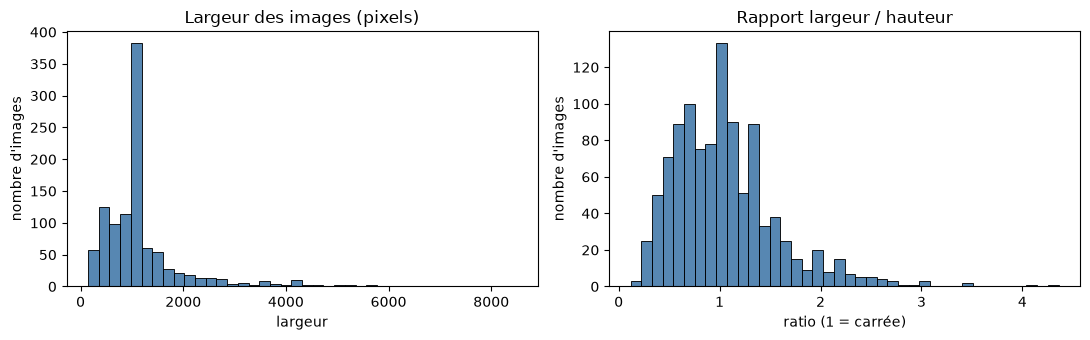

In [3]:
tailles = []
for chemin in df["chemin_image"]:
    with Image.open(chemin) as image:
        tailles.append((*image.size, image.mode))
df[["largeur", "hauteur", "mode"]] = pd.DataFrame(tailles, index=df.index)
df["ratio"] = df["largeur"] / df["hauteur"]

print(df[["largeur", "hauteur", "ratio"]].describe().round(2).to_string())
print("\nModes de couleur :", df["mode"].value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df["largeur"], bins=40, ax=axes[0], color="#1f5f99")
axes[0].set(title="Largeur des images (pixels)", xlabel="largeur", ylabel="nombre d'images")
sns.histplot(df["ratio"], bins=40, ax=axes[1], color="#1f5f99")
axes[1].set(title="Rapport largeur / hauteur", xlabel="ratio (1 = carrée)", ylabel="nombre d'images")
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "eda_tailles.png", dpi=150)
plt.show()

Les tailles vont de moins de 200 pixels à plus de 11 000 pixels de côté, et beaucoup d'images ne sont
pas carrées. Tous les modèles attendent une image carrée de 224 × 224 pixels : la préparation doit
donc gérer ces formats sans déformer ni couper le produit (section 2).

### Un exemple d'image par catégorie

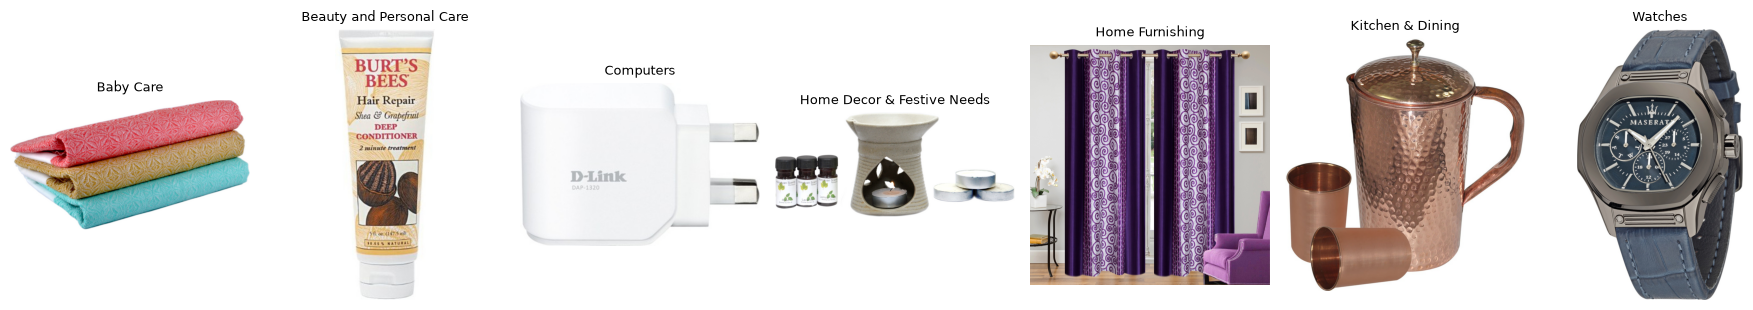

In [4]:
fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(18, 3.2))
for ax, categorie in zip(axes, CATEGORIES):
    chemin = df.loc[df["categorie"] == categorie, "chemin_image"].iloc[0]
    with Image.open(chemin) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(categorie, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "eda_exemples.png", dpi=120)
plt.show()

### Y a-t-il des images en double ?

Si la même photo apparaissait deux fois, une copie pourrait tomber dans les données d'entraînement et
l'autre dans les données de test : le modèle serait alors évalué sur une image qu'il a déjà vue, et le
score serait gonflé. On le vérifie avec une **empreinte perceptuelle** : l'image est réduite à 8 × 8
pixels en niveaux de gris, puis chaque pixel est codé 1 s'il est plus clair que la moyenne, 0 sinon.
Deux photos quasi identiques ont des empreintes qui diffèrent de très peu de bits.

In [5]:
def empreinte(chemin, cote=8):
    with Image.open(chemin) as image:
        petit = np.asarray(image.convert("L").resize((cote, cote), Image.LANCZOS), dtype=np.float32)
    return (petit > petit.mean()).flatten()


empreintes = np.stack([empreinte(c) for c in df["chemin_image"]])
distances = (empreintes[:, None, :] != empreintes[None, :, :]).sum(axis=2)
np.fill_diagonal(distances, 99)
paires = np.argwhere(np.triu(distances <= 2))
print("Paires d'images quasi identiques (au plus 2 bits d'écart sur 64) :", len(paires))
print("dont paires de catégories différentes :",
      sum(df["categorie"].iloc[i] != df["categorie"].iloc[j] for i, j in paires))

Paires d'images quasi identiques (au plus 2 bits d'écart sur 64) : 258
dont paires de catégories différentes : 13


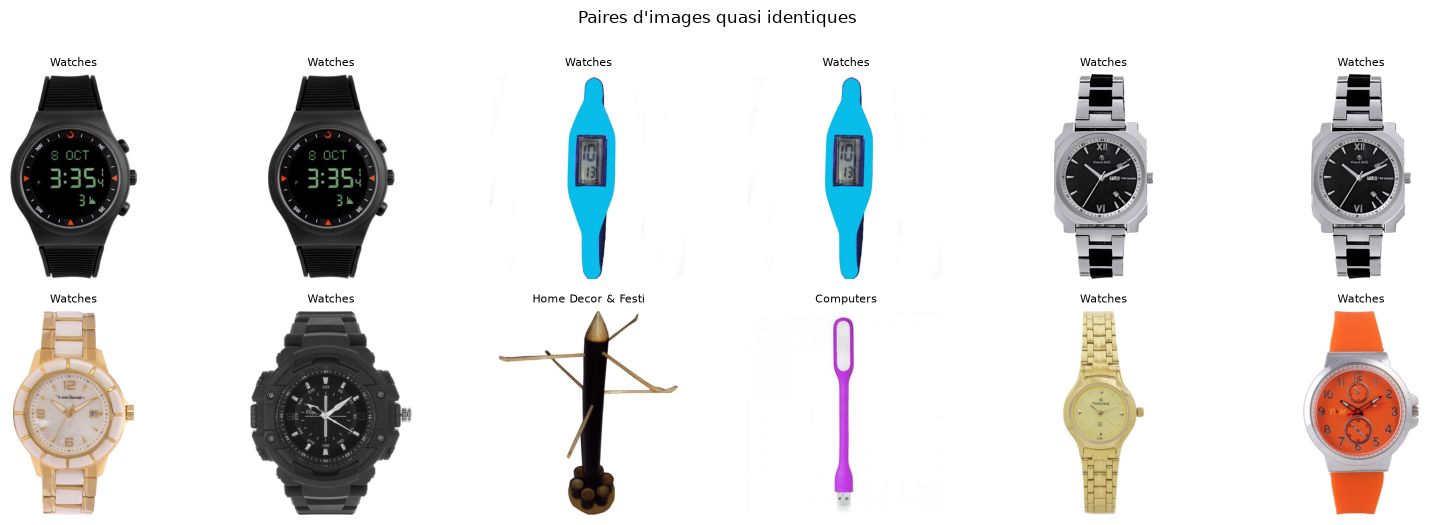

In [6]:
if len(paires):
    montrer = paires[:6]
    fig, axes = plt.subplots(2, len(montrer), figsize=(2.6 * len(montrer), 5.2), squeeze=False)
    for k, (i, j) in enumerate(montrer):
        for ligne, idx in enumerate((i, j)):
            with Image.open(df["chemin_image"].iloc[idx]) as image:
                axes[ligne, k].imshow(image.convert("RGB"))
            axes[ligne, k].set_title(df["categorie"].iloc[idx][:18], fontsize=8)
            axes[ligne, k].axis("off")
    plt.suptitle("Paires d'images quasi identiques", y=1.0)
    plt.tight_layout()
    plt.show()

Les quasi-doublons repérés sont des variantes d'un même article (même photo, coloris ou taille
différents). Pour qu'une copie ne puisse jamais se retrouver d'un côté de l'entraînement et l'autre côté
du test, **on regroupe les quasi-doublons et on garde chaque groupe entier dans le même pli** de
validation (section 4).

In [7]:
# Regroupement des quasi-doublons en composantes connexes (union-find)
parent = list(range(len(df)))


def racine(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


for i, j in paires:
    parent[racine(i)] = racine(j)
groupes = np.array([racine(i) for i in range(len(df))])
print("Images :", len(df), "| groupes après regroupement des quasi-doublons :", len(np.unique(groupes)))

Images : 1050 | groupes après regroupement des quasi-doublons : 933


## 2. La préparation des images

Au projet 6, les images étaient redimensionnées directement en 224 × 224, ce qui **déforme** les
produits non carrés (une montre devient ovale). L'autre réflexe courant, recadrer le centre, risque de
**couper** le produit sur les images très allongées.

On choisit donc de **compléter l'image en carré avec du blanc**, puis de la réduire en 224 × 224.
Le blanc est la couleur de fond de la plupart des photos de catalogue, donc ce bord ajouté passe
inaperçu. Enfin on normalise les couleurs avec la moyenne et l'écart-type d'ImageNet, attendus par les
quatre réseaux.

Cette préparation est **la même pour les quatre modèles**, et la même que dans le dashboard.

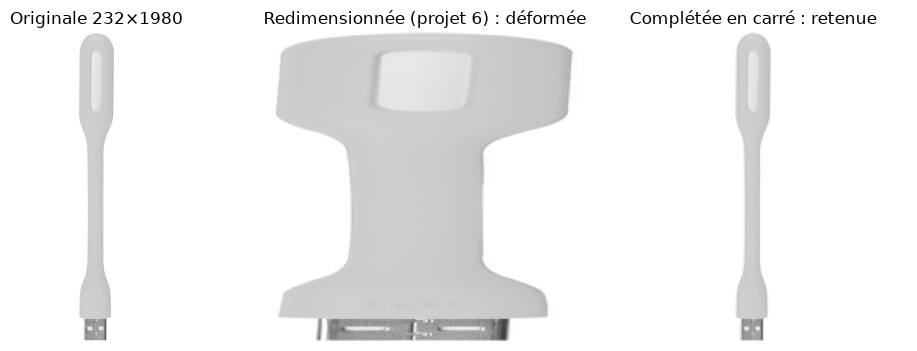

In [8]:
TAILLE = 224
MOYENNE_IMAGENET = np.array([0.485, 0.456, 0.406], dtype=np.float32)
ECART_TYPE_IMAGENET = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def carre_blanc(image: Image.Image, taille: int = TAILLE) -> Image.Image:
    """Complète l'image en carré avec du blanc, sans la déformer, puis la réduit."""
    image = image.convert("RGB")
    cote = max(image.size)
    fond = Image.new("RGB", (cote, cote), (255, 255, 255))
    fond.paste(image, ((cote - image.width) // 2, (cote - image.height) // 2))
    return fond.resize((taille, taille), Image.BICUBIC)


def vers_tenseur(image: Image.Image) -> torch.Tensor:
    """Image carrée 224 × 224 → tenseur normalisé (3, 224, 224)."""
    tableau = np.asarray(image, dtype=np.float32) / 255.0
    tableau = (tableau - MOYENNE_IMAGENET) / ECART_TYPE_IMAGENET
    return torch.from_numpy(tableau.transpose(2, 0, 1))


exemple = df.loc[df["ratio"].idxmin()]
with Image.open(exemple["chemin_image"]) as image:
    original = image.convert("RGB")
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
axes[0].imshow(original); axes[0].set_title(f"Originale {original.size[0]}×{original.size[1]}")
axes[1].imshow(original.resize((TAILLE, TAILLE))); axes[1].set_title("Redimensionnée (projet 6) : déformée")
axes[2].imshow(carre_blanc(original)); axes[2].set_title("Complétée en carré : retenue")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "preparation_image.png", dpi=130)
plt.show()

In [9]:
# Les 1 050 images préparées sont gardées en mémoire une fois pour toutes :
# 1 050 × 3 × 224 × 224 nombres sur 4 octets, soit environ 630 Mo.
debut = time.perf_counter()
tenseurs = torch.stack([vers_tenseur(carre_blanc(Image.open(c))) for c in df["chemin_image"]])
print("Tenseur des images :", tuple(tenseurs.shape),
      f"| préparé en {time.perf_counter() - debut:.0f} s")

Tenseur des images : (1050, 3, 224, 224) | préparé en 37 s


## 3. Les représentations d'images

Chaque réseau gelé transforme une image en un vecteur :

- MobileNetV2 et ResNet50 : la sortie de la dernière couche convolutive, moyennée sur l'image
  (« global average pooling »), soit 1 280 et 2 048 nombres. Au projet 6, c'est ce vecteur de MobileNetV2
  qui était branché sur la couche de classification, et ce vecteur de ResNet50 qui servait au clustering.
- DINOv2 : le vecteur est la concaténation du jeton [CLS], qui résume l'image entière, et de la moyenne
  des jetons des 256 patchs, qui décrivent chacun un carré de 14 × 14 pixels. Soit 2 × 384 = 768 nombres
  pour ViT-S et 2 × 768 = 1 536 pour ViT-B. C'est la construction utilisée par les classifieurs linéaires
  que Meta publie avec DINOv2 (fichier `dinov2/hub/classifiers.py` du dépôt officiel, version à une
  couche) : on reprend donc la façon dont les auteurs eux-mêmes branchent un classifieur sur le modèle.

On utilise la variante de DINOv2 avec registres (Darcet et al., « Vision Transformers Need Registers »,
2023, même équipe Meta). Piège rencontré à la première exécution : avec la version sans registres, les
cartes d'attention montraient surtout le coin en haut à gauche et quelques points du fond blanc. Mesuré
sur 42 images : un seul patch de fond, celui du coin, captait 15,1 % de l'attention. C'est l'artefact
décrit par cet article : le modèle détourne quelques patchs de fond peu informatifs pour y stocker des
informations globales. La variante avec registres ajoute 4 jetons prévus pour ce rôle ; sur les mêmes
42 images, le patch du coin ne reçoit plus que 0,1 % de l'attention et le produit en reçoit 89 %, contre
64 % sans registres. Les explications de la section 6 ne seraient pas fiables sans ce changement.


In [10]:
class ReseauConvolutif(torch.nn.Module):
    """Un réseau torchvision dont on garde la sortie moyennée de la dernière couche convolutive."""

    def __init__(self, nom):
        super().__init__()
        if nom == "mobilenet_v2":
            reseau = tv_models.mobilenet_v2(weights=tv_models.MobileNet_V2_Weights.IMAGENET1K_V1)
            self.corps = reseau.features
        else:
            reseau = tv_models.resnet50(weights=tv_models.ResNet50_Weights.IMAGENET1K_V2)
            self.corps = torch.nn.Sequential(*list(reseau.children())[:-2])

    def forward(self, x):
        return self.corps(x).mean(dim=(2, 3))


class DINOv2(torch.nn.Module):
    """DINOv2 avec registres (Hugging Face) ; renvoie [CLS] concaténé à la moyenne des 256 patchs."""

    def __init__(self, nom_hf):
        super().__init__()
        self.reseau = AutoModel.from_pretrained(nom_hf)
        # Les jetons sortent dans l'ordre : [CLS], puis les registres (4 ici), puis les 256 patchs.
        # Les registres ne correspondent à aucun morceau de l'image : on les écarte de la moyenne.
        self.nb_registres = self.reseau.config.num_register_tokens

    def forward(self, x):
        jetons = self.reseau(pixel_values=x).last_hidden_state   # (lot, 1 + 4 + 256, dimension)
        patchs = jetons[:, 1 + self.nb_registres:]
        return torch.cat([jetons[:, 0], patchs.mean(dim=1)], dim=1)


MODELES = {
    "MobileNetV2": dict(role="baseline", construire=lambda: ReseauConvolutif("mobilenet_v2")),
    "ResNet50": dict(role="baseline", construire=lambda: ReseauConvolutif("resnet50")),
    "DINOv2-reg ViT-S/14": dict(role="nouveau", construire=lambda: DINOv2("facebook/dinov2-with-registers-small")),
    "DINOv2-reg ViT-B/14": dict(role="nouveau", construire=lambda: DINOv2("facebook/dinov2-with-registers-base")),
}


@torch.no_grad()
def extraire(reseau, images, taille_lot=32):
    reseau.eval().to(APPAREIL)
    sorties = []
    for i in range(0, len(images), taille_lot):
        sorties.append(reseau(images[i:i + taille_lot].to(APPAREIL)).float().cpu())
    return torch.cat(sorties).numpy()


representations, reseaux, fiches = {}, {}, []
for nom, info in MODELES.items():
    fichier = DOSSIER_TRAVAIL / f"representations_{nom.replace('/', '-').replace(' ', '_')}.npy"
    reseau = info["construire"]()
    # Les représentations sont mises en cache : relancer le notebook ne refait pas les
    # extractions, qui prennent plusieurs minutes chacune.
    if fichier.exists():
        X = np.load(fichier)
    else:
        X = extraire(reseau, tenseurs)
        np.save(fichier, X)
    representations[nom] = X
    reseaux[nom] = reseau.eval()
    fiches.append({"modèle": nom, "rôle": info["role"],
                   "paramètres (M)": round(sum(p.numel() for p in reseau.parameters()) / 1e6, 1),
                   "dimension": X.shape[1]})
    print(f"{nom:<20} → {X.shape}")

MobileNetV2          → (1050, 1280)


ResNet50             → (1050, 2048)


Loading weights:   0%|          | 0/224 [00:00<?, ?it/s]

DINOv2-reg ViT-S/14  → (1050, 768)


Loading weights:   0%|          | 0/224 [00:00<?, ?it/s]

DINOv2-reg ViT-B/14  → (1050, 1536)


### Le temps de prédiction d'une image

On mesure le temps pour classer une seule image sur processeur, la situation du dashboard. Cette mesure
a demandé du soin.

Piège rencontré : mesurés un modèle après l'autre, les temps changeaient du simple au triple d'une
exécution à l'autre (ResNet50 entre 41 et 315 ms), et ResNet50 sortait parfois plus lent que DINOv2-S,
ce qui n'a pas de sens vu leurs tailles. Deux causes, vérifiées par un essai à part :

- chaque modèle était mesuré à un moment différent, donc dans un état différent de la machine (un
  portable ralentit quand il chauffe ou quand un autre programme travaille) ;
- le processeur de ce portable (Intel i7-13620H) a 6 cœurs rapides et 4 cœurs lents, et PyTorch
  utilise par défaut tous les cœurs : selon ceux que Windows lui attribue, un même calcul va plus ou
  moins vite. Mesuré deux fois de suite, DINOv2-B passait de 471 à 588 ms avec tous les cœurs, contre
  600 et 596 ms limité à 6 cœurs.

La mesure retenue limite donc PyTorch à 6 cœurs, alterne les quatre modèles dans un ordre tiré au
hasard à chaque tour (ils subissent ainsi les mêmes conditions), répète 40 tours, et garde la médiane,
qui n'est pas tirée par quelques mesures aberrantes. On donne aussi le rapport avec MobileNetV2, plus
parlant qu'une valeur absolue qui dépend de la machine.

In [11]:
import random

NB_COEURS_MESURE, NB_TOURS = 6, 40
coeurs_avant = torch.get_num_threads()
torch.set_num_threads(NB_COEURS_MESURE)
random.seed(GRAINE)
une_image = tenseurs[:1]
chronos = {nom: [] for nom in reseaux}
with torch.no_grad():
    for nom, reseau in reseaux.items():          # quelques passages « à vide » pour chauffer les caches
        for _ in range(3):
            reseau(une_image)
    for _ in range(NB_TOURS):
        ordre = list(reseaux)
        random.shuffle(ordre)
        for nom in ordre:
            debut = time.perf_counter()
            reseaux[nom](une_image)
            chronos[nom].append(1000 * (time.perf_counter() - debut))
torch.set_num_threads(coeurs_avant)

mediane_base = np.median(chronos["MobileNetV2"])
for fiche in fiches:
    mesures = chronos[fiche["modèle"]]
    fiche["temps par image, CPU (ms)"] = round(float(np.median(mesures)), 1)
    fiche["moitié des mesures entre (ms)"] = f"{np.percentile(mesures, 25):.0f} et {np.percentile(mesures, 75):.0f}"
    fiche["fois plus lent que MobileNetV2"] = round(float(np.median(mesures) / mediane_base), 1)
del reseaux

fiche_modeles = pd.DataFrame(fiches).set_index("modèle")
fiche_modeles

,rôle,paramètres (M),dimension,"temps par image, CPU (ms)",moitié des mesures entre (ms),fois plus lent que MobileNetV2
modèle,,,,,,
MobileNetV2,baseline,2.2,1280,35.9,29 et 44,1.0
ResNet50,baseline,23.5,2048,129.6,114 et 152,3.6
DINOv2-reg ViT-S/14,nouveau,22.1,768,165.7,128 et 180,4.6
DINOv2-reg ViT-B/14,nouveau,86.6,1536,588.7,482 et 633,16.4


### Première impression : la carte t-SNE des représentations

Avant tout classifieur, on projette chaque représentation en 2 dimensions avec t-SNE, une méthode qui
place côte à côte les images dont les vecteurs se ressemblent. Si les couleurs (les vraies catégories)
forment des îlots bien séparés, la représentation « comprend » déjà les catégories sans les avoir
apprises. C'est l'analyse de faisabilité du projet 6, refaite pour les quatre réseaux.

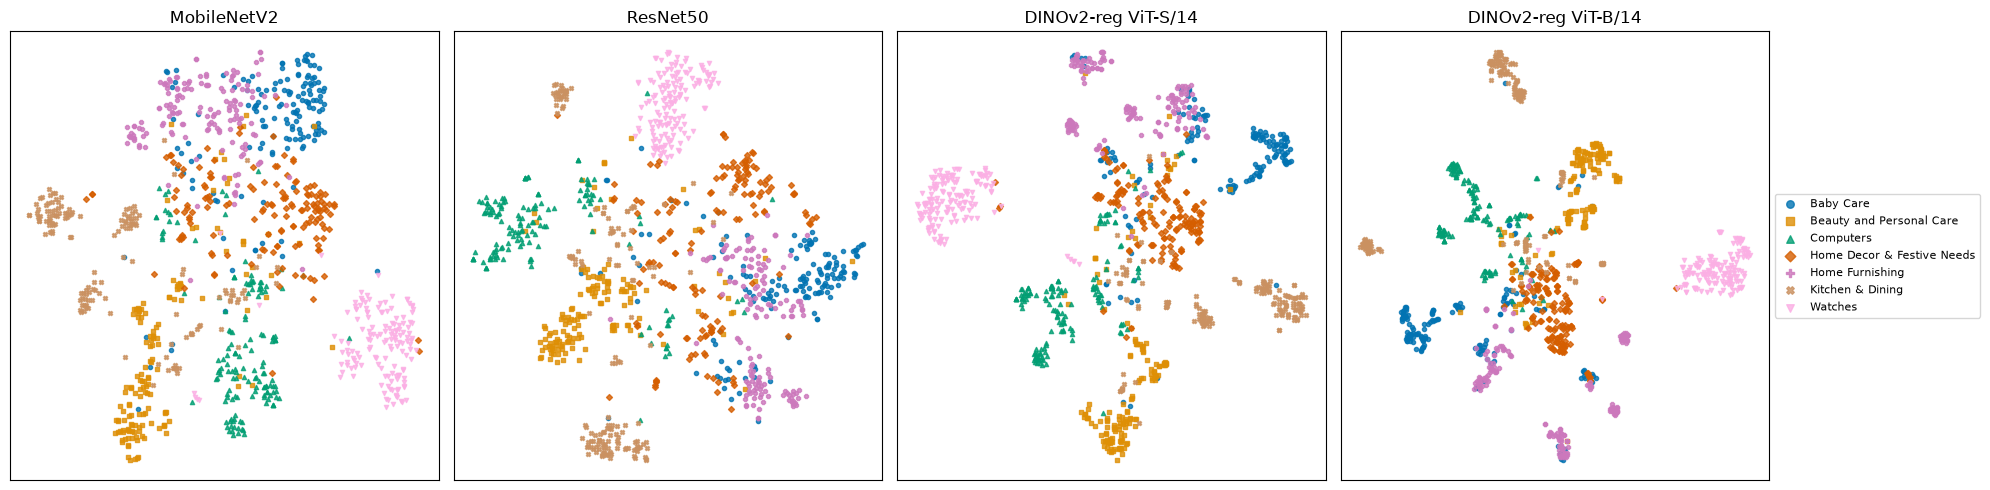

In [12]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

PALETTE = dict(zip(CATEGORIES, sns.color_palette("colorblind", len(CATEGORIES))))
MARQUEURS = dict(zip(CATEGORIES, ["o", "s", "^", "D", "P", "X", "v"]))

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (nom, X) in zip(axes, representations.items()):
    X50 = PCA(n_components=50, random_state=GRAINE).fit_transform(StandardScaler().fit_transform(X))
    X2 = TSNE(n_components=2, init="pca", perplexity=30, random_state=GRAINE).fit_transform(X50)
    for categorie in CATEGORIES:
        masque = df["categorie"].to_numpy() == categorie
        ax.scatter(X2[masque, 0], X2[masque, 1], s=9, alpha=0.8, color=PALETTE[categorie],
                   marker=MARQUEURS[categorie], label=categorie)
    ax.set_title(nom)
    ax.set_xticks([]); ax.set_yticks([])
axes[-1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8, markerscale=1.8)
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "tsne_representations.png", dpi=130, bbox_inches="tight")
plt.show()

## 4. L'entraînement et l'évaluation

### Le classifieur

Sur chaque représentation, on entraîne le même classifieur : une **régression logistique multinomiale**,
précédée d'une standardisation des variables. C'est mathématiquement la même chose que la couche dense
« softmax » du projet 6 : une combinaison linéaire des features suivie d'un softmax. Son seul réglage est
**C**, l'inverse de la force de régularisation : un petit C empêche le modèle d'apprendre par cœur les
quelques centaines d'images d'entraînement.

### Le protocole : une validation croisée imbriquée, groupée et stratifiée

Avec seulement 1 050 images, un seul découpage entraînement / test (210 images de test au projet 6)
donne un score qui dépend beaucoup du hasard du découpage. On utilise donc une **validation croisée en
5 plis** :

- les images sont réparties en 5 plis de 210 images, chaque catégorie étant représentée à parts égales
  dans chaque pli (*stratifiée*), et les quasi-doublons restant ensemble (*groupée*) ;
- tour à tour, chaque pli sert de test, et le modèle est entraîné sur les 4 autres ;
- **à l'intérieur** de ces 4 plis d'entraînement, une seconde validation croisée en 5 plis choisit le
  meilleur C (*imbriquée*). Le pli de test n'intervient jamais dans le choix du réglage, sinon le score
  serait optimiste.

À la fin, **chaque image a été prédite exactement une fois, par un modèle qui ne l'avait jamais vue**.
Les mêmes plis servent aux quatre modèles, ce qui permet de les comparer image par image.

In [13]:
from sklearn.model_selection import StratifiedGroupKFold

NB_PLIS = 5
GRILLE_C = {"logisticregression__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]}

plis = list(StratifiedGroupKFold(n_splits=NB_PLIS, shuffle=True, random_state=GRAINE)
            .split(np.zeros(len(y)), y, groups=groupes))
for k, (entrainement, test) in enumerate(plis):
    print(f"pli {k + 1} : {len(entrainement)} images d'entraînement, {len(test)} de test, "
          f"par catégorie en test : {np.bincount(y[test]).tolist()}")


def nouveau_classifieur():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))


def evaluer(X):
    """Validation croisée imbriquée : renvoie les probabilités prédites hors pli et les C choisis."""
    probabilites = np.zeros((len(y), len(CATEGORIES)))
    c_choisis = []
    for entrainement, test in plis:
        recherche = GridSearchCV(
            nouveau_classifieur(), GRILLE_C, scoring="accuracy",
            cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=GRAINE), n_jobs=N_PROCESSUS)
        recherche.fit(X[entrainement], y[entrainement], groups=groupes[entrainement])
        probabilites[test] = recherche.predict_proba(X[test])
        c_choisis.append(recherche.best_params_["logisticregression__C"])
    return probabilites, c_choisis


resultats = {}
for nom, X in representations.items():
    debut = time.perf_counter()
    probabilites, c_choisis = evaluer(X)
    predictions = probabilites.argmax(axis=1)
    scores_plis = [accuracy_score(y[test], predictions[test]) for _, test in plis]
    resultats[nom] = dict(probabilites=probabilites, predictions=predictions,
                          scores_plis=scores_plis, c_choisis=c_choisis)
    print(f"{nom:<16} exactitude {accuracy_score(y, predictions):.3f} "
          f"(plis : {' / '.join(f'{s:.3f}' for s in scores_plis)}) | C choisis : {c_choisis} "
          f"| {time.perf_counter() - debut:.0f} s")

pli 1 : 840 images d'entraînement, 210 de test, par catégorie en test : [30, 30, 30, 30, 30, 30, 30]
pli 2 : 840 images d'entraînement, 210 de test, par catégorie en test : [30, 30, 30, 30, 30, 30, 30]
pli 3 : 840 images d'entraînement, 210 de test, par catégorie en test : [30, 30, 30, 30, 30, 30, 30]
pli 4 : 840 images d'entraînement, 210 de test, par catégorie en test : [30, 30, 30, 30, 30, 30, 30]
pli 5 : 840 images d'entraînement, 210 de test, par catégorie en test : [30, 30, 30, 30, 30, 30, 30]


MobileNetV2      exactitude 0.830 (plis : 0.819 / 0.819 / 0.819 / 0.857 / 0.838) | C choisis : [0.001, 0.001, 0.01, 0.001, 0.01] | 24 s


ResNet50         exactitude 0.879 (plis : 0.857 / 0.881 / 0.905 / 0.900 / 0.852) | C choisis : [1.0, 0.003, 0.003, 0.003, 0.003] | 19 s


DINOv2-reg ViT-S/14 exactitude 0.898 (plis : 0.881 / 0.919 / 0.886 / 0.938 / 0.867) | C choisis : [0.01, 0.003, 0.3, 0.01, 0.003] | 13 s


DINOv2-reg ViT-B/14 exactitude 0.928 (plis : 0.938 / 0.924 / 0.938 / 0.952 / 0.886) | C choisis : [0.01, 0.003, 0.003, 0.001, 0.003] | 19 s


## 5. Les résultats

### Le tableau de comparaison

L'intervalle de confiance à 95 % de l'exactitude est obtenu par *bootstrap* : on retire 2 000 fois au
hasard, avec remise, 1 050 images parmi les 1 050 prédictions, et on regarde entre quelles valeurs
tombe l'exactitude dans 95 % des tirages.

In [14]:
rng = np.random.default_rng(GRAINE)
tirages = rng.integers(0, len(y), size=(2000, len(y)))


def intervalle(correct):
    moyennes = correct[tirages].mean(axis=1)
    return np.percentile(moyennes, [2.5, 97.5])


lignes = []
for nom, r in resultats.items():
    correct = (r["predictions"] == y).astype(float)
    bas, haut = intervalle(correct)
    lignes.append({
        "modèle": nom,
        "rôle": MODELES[nom]["role"],
        "exactitude": correct.mean(),
        "IC 95 %": f"[{bas:.3f} ; {haut:.3f}]",
        "écart-type entre plis": np.std(r["scores_plis"]),
        "F1 macro": f1_score(y, r["predictions"], average="macro"),
        "erreurs / 1 050": int((1 - correct).sum()),
    })
tableau = (pd.DataFrame(lignes).set_index("modèle")
           .join(fiche_modeles[["paramètres (M)", "temps par image, CPU (ms)", "fois plus lent que MobileNetV2"]]))
tableau.to_csv(DOSSIER_TRAVAIL / "tableau_resultats.csv")
tableau.style.format({"exactitude": "{:.3f}", "écart-type entre plis": "{:.3f}", "F1 macro": "{:.3f}"})

,rôle,exactitude,IC 95 %,écart-type entre plis,F1 macro,erreurs / 1 050,paramètres (M),"temps par image, CPU (ms)",fois plus lent que MobileNetV2
modèle,,,,,,,,,
MobileNetV2,baseline,0.830,[0.808 ; 0.852],0.015,0.830,178,2.200000,35.900000,1.000000
ResNet50,baseline,0.879,[0.859 ; 0.898],0.021,0.878,127,23.500000,129.600000,3.600000
DINOv2-reg ViT-S/14,nouveau,0.898,[0.880 ; 0.915],0.026,0.898,107,22.100000,165.700000,4.600000
DINOv2-reg ViT-B/14,nouveau,0.928,[0.911 ; 0.943],0.023,0.927,76,86.600000,588.700000,16.400000


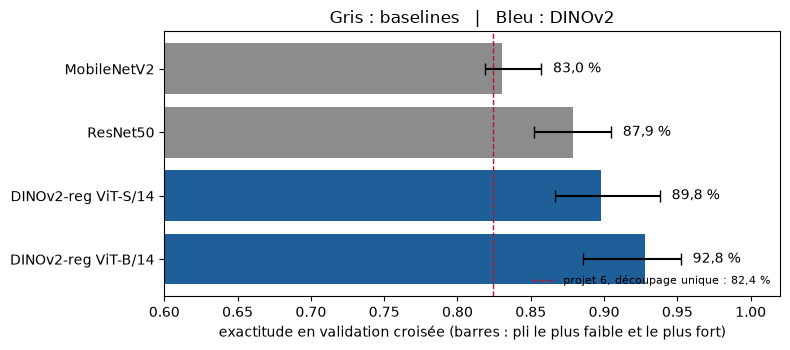

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ordre = list(resultats)
couleurs = ["#8c8c8c" if MODELES[n]["role"] == "baseline" else "#1f5f99" for n in ordre]
valeurs = [tableau.loc[n, "exactitude"] for n in ordre]
barres = ax.barh(ordre, valeurs, color=couleurs)
for barre, n in zip(barres, ordre):
    plis_n = resultats[n]["scores_plis"]
    ax.errorbar(barre.get_width(), barre.get_y() + barre.get_height() / 2,
                xerr=[[barre.get_width() - min(plis_n)], [max(plis_n) - barre.get_width()]],
                color="black", capsize=4)
    # la valeur est écrite à droite de la barre d'erreur, pour ne pas la chevaucher
    ax.text(max(plis_n) + 0.008, barre.get_y() + barre.get_height() / 2,
            f"{100 * barre.get_width():.1f} %".replace(".", ","), va="center", fontsize=10)
ax.axvline(0.824, ls="--", color="#b2182b", lw=1, label="projet 6, découpage unique : 82,4 %")
ax.legend(loc="lower right", fontsize=8, frameon=False)
ax.set_xlim(0.6, 1.02)
ax.invert_yaxis()
ax.set_xlabel("exactitude en validation croisée (barres : pli le plus faible et le plus fort)")
ax.set_title("Gris : baselines   |   Bleu : DINOv2")
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "comparaison_exactitude.png", dpi=150)
plt.show()

### L'écart est-il significatif ? Le test de McNemar

Les modèles ont jugé exactement les mêmes images. Le test de McNemar ne regarde que les images sur
lesquelles deux modèles **ne sont pas d'accord** : celles que seul le premier réussit (b) et celles que
seul le second réussit (c). Si les deux modèles se valaient, ces désaccords se répartiraient à peu près
moitié-moitié. La p-valeur est la probabilité d'observer un déséquilibre au moins aussi fort par hasard.
On utilise la version exacte (loi binomiale), adaptée quand les désaccords sont peu nombreux.

In [16]:
def comparer(nom_a, nom_b):
    juste_a = resultats[nom_a]["predictions"] == y
    juste_b = resultats[nom_b]["predictions"] == y
    b = int((juste_a & ~juste_b).sum())
    c = int((~juste_a & juste_b).sum())
    test = mcnemar([[int((juste_a & juste_b).sum()), b], [c, int((~juste_a & ~juste_b).sum())]],
                   exact=True)
    ecart = juste_b.mean() - juste_a.mean()
    bas, haut = np.percentile((juste_b.astype(float) - juste_a)[tirages].mean(axis=1), [2.5, 97.5])
    return {"comparaison": f"{nom_b}  vs  {nom_a}",
            "seul A juste (b)": b, "seul B juste (c)": c,
            "écart (points)": round(100 * ecart, 1),
            "IC 95 % de l'écart": f"[{100 * bas:+.1f} ; {100 * haut:+.1f}]",
            "p-valeur McNemar": test.pvalue}


comparaisons = pd.DataFrame([
    comparer("MobileNetV2", "DINOv2-reg ViT-B/14"),
    comparer("ResNet50", "DINOv2-reg ViT-B/14"),
    comparer("ResNet50", "DINOv2-reg ViT-S/14"),          # à taille comparable
    comparer("MobileNetV2", "DINOv2-reg ViT-S/14"),
    comparer("DINOv2-reg ViT-S/14", "DINOv2-reg ViT-B/14"),   # l'apport de la taille, à méthode égale
]).set_index("comparaison")

# On fait 5 tests d'un coup : avec un seuil de 5 % par test, le risque qu'au moins un test
# soit « significatif » par pur hasard dépasse 5 %. La correction de Bonferroni, la plus
# simple et la plus prudente, multiplie chaque p-valeur par le nombre de tests (plafonnée à 1).
nb_tests = len(comparaisons)
comparaisons["p-valeur corrigée (Bonferroni)"] = (comparaisons["p-valeur McNemar"] * nb_tests).clip(upper=1)
comparaisons["significatif au seuil de 5 %"] = np.where(
    comparaisons["p-valeur corrigée (Bonferroni)"] < 0.05, "oui", "non")
comparaisons.to_csv(DOSSIER_TRAVAIL / "tests_mcnemar.csv")
comparaisons.style.format({"p-valeur McNemar": "{:.1e}", "p-valeur corrigée (Bonferroni)": "{:.1e}"})

,seul A juste (b),seul B juste (c),écart (points),IC 95 % de l'écart,p-valeur McNemar,p-valeur corrigée (Bonferroni),significatif au seuil de 5 %
comparaison,,,,,,,
DINOv2-reg ViT-B/14 vs MobileNetV2,13,115,9.700000,[+7.7 ; +11.8],1.4e-21,7.0e-21,oui
DINOv2-reg ViT-B/14 vs ResNet50,19,70,4.900000,[+3.1 ; +6.6],5.0e-08,2.5e-07,oui
DINOv2-reg ViT-S/14 vs ResNet50,31,51,1.900000,[+0.2 ; +3.5],3.5e-02,1.8e-01,non
DINOv2-reg ViT-S/14 vs MobileNetV2,23,94,6.800000,[+4.8 ; +8.9],2.2e-11,1.1e-10,oui
DINOv2-reg ViT-B/14 vs DINOv2-reg ViT-S/14,10,41,3.000000,[+1.7 ; +4.4],1.5e-05,7.4e-05,oui


### Le détail par catégorie et la matrice de confusion

On compare la baseline du projet 6 (MobileNetV2) et le meilleur DINOv2.

In [17]:
# Le nouveau modèle retenu est fixé à l'avance, comme annoncé dans le plan prévisionnel :
# DINOv2-reg ViT-B/14. On ne le choisit pas en prenant le meilleur score ci-dessus, car ces
# scores sont nos scores de test : choisir sur eux rendrait le chiffre annoncé optimiste.
# (ViT-S/14 sert de comparaison à taille égale avec ResNet50, pas de candidat.)
MEILLEUR = "DINOv2-reg ViT-B/14"
BASELINE = "MobileNetV2"
print("Nouveau modèle :", MEILLEUR, "| baseline :", BASELINE)

par_categorie = pd.DataFrame({
    f"F1 {BASELINE}": f1_score(y, resultats[BASELINE]["predictions"], average=None),
    f"F1 {MEILLEUR}": f1_score(y, resultats[MEILLEUR]["predictions"], average=None),
}, index=CATEGORIES)
par_categorie["gain (points)"] = (100 * (par_categorie.iloc[:, 1] - par_categorie.iloc[:, 0])).round(1)
par_categorie.round(3)

Nouveau modèle : DINOv2-reg ViT-B/14 | baseline : MobileNetV2


,F1 MobileNetV2,F1 DINOv2-reg ViT-B/14,gain (points)
Baby Care,0.764,0.859,9.5
Beauty and Personal Care,0.815,0.902,8.7
Computers,0.858,0.954,9.6
Home Decor & Festive Needs,0.779,0.917,13.7
Home Furnishing,0.800,0.924,12.4
Kitchen & Dining,0.825,0.949,12.4
Watches,0.970,0.987,1.7


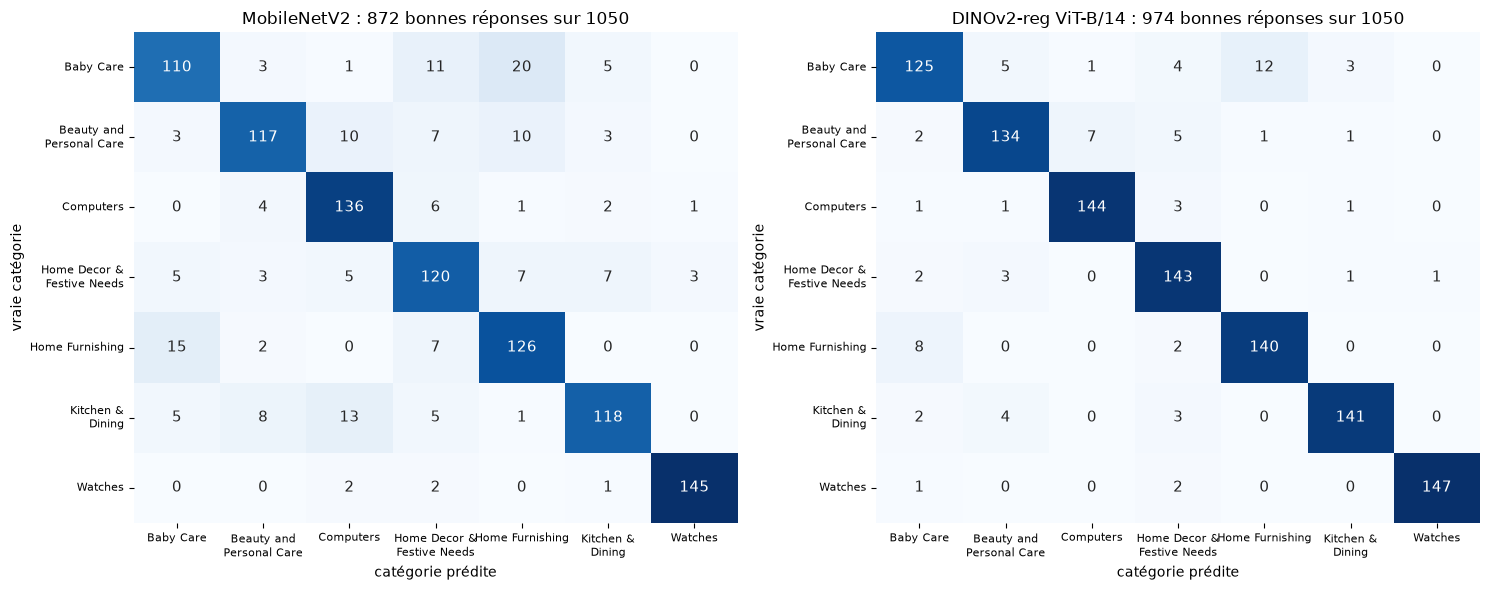

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
etiquettes = [c.replace(" & ", " &\n").replace(" and ", " and\n") for c in CATEGORIES]
for ax, nom in zip(axes, (BASELINE, MEILLEUR)):
    matrice = confusion_matrix(y, resultats[nom]["predictions"])
    sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=etiquettes, yticklabels=etiquettes, annot_kws={"size": 11})
    ax.set_title(f"{nom} : {np.trace(matrice)} bonnes réponses sur {matrice.sum()}")
    ax.set_xlabel("catégorie prédite"); ax.set_ylabel("vraie catégorie")
    ax.tick_params(axis="x", labelsize=8, rotation=0); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "matrices_confusion.png", dpi=130)
plt.show()

### Le contrôle de continuité avec le projet 6

Pour relier ces résultats à ceux du projet 6, on reproduit son découpage unique : 80 % d'entraînement,
20 % de validation, stratifié, graine 42. Le classifieur est réglé par validation croisée sur les 80 %
seulement.

In [19]:
idx_entrainement, idx_validation = train_test_split(
    np.arange(len(y)), test_size=0.2, random_state=42, stratify=y)
continuite = {}
for nom, X in representations.items():
    recherche = GridSearchCV(nouveau_classifieur(), GRILLE_C, cv=5, n_jobs=N_PROCESSUS)
    recherche.fit(X[idx_entrainement], y[idx_entrainement])
    continuite[nom] = accuracy_score(y[idx_validation], recherche.predict(X[idx_validation]))
pd.Series(continuite, name="exactitude, découpage du projet 6 (210 images)").round(3).to_frame()

,"exactitude, découpage du projet 6 (210 images)"
MobileNetV2,0.867
ResNet50,0.843
DINOv2-reg ViT-S/14,0.910
DINOv2-reg ViT-B/14,0.929


### Les images que DINOv2 se trompe encore

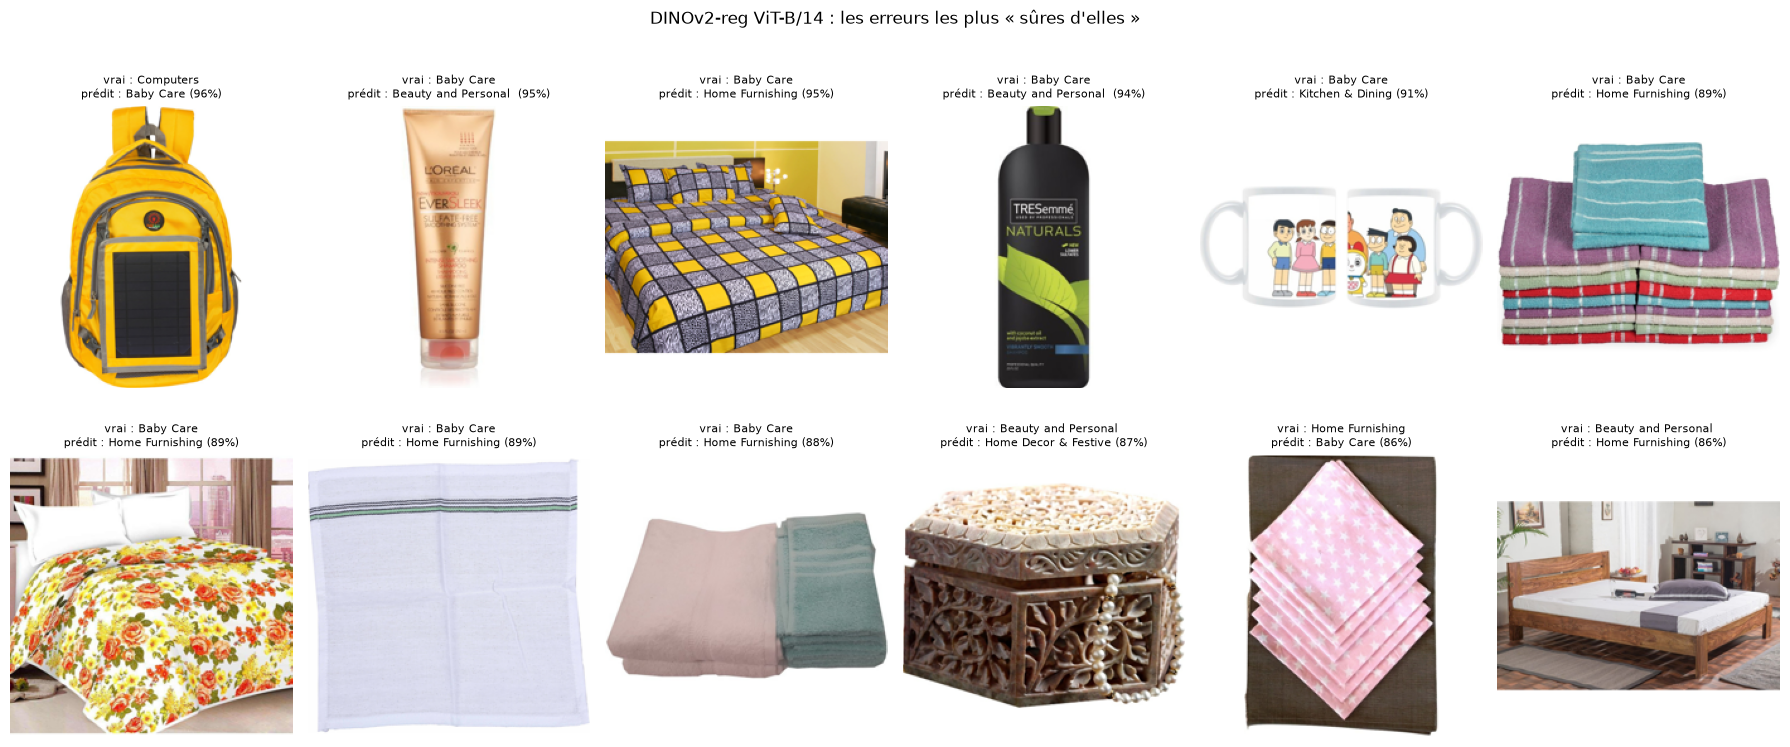

In [20]:
erreurs = np.where(resultats[MEILLEUR]["predictions"] != y)[0]
confiance = resultats[MEILLEUR]["probabilites"].max(axis=1)
montrer = erreurs[np.argsort(-confiance[erreurs])][:12]
fig, axes = plt.subplots(2, 6, figsize=(18, 7.6))
for ax, i in zip(axes.flat, montrer):
    with Image.open(df["chemin_image"].iloc[i]) as image:
        ax.imshow(carre_blanc(image))
    ax.set_title(f"vrai : {CATEGORIES[y[i]][:20]}\nprédit : "
                 f"{CATEGORIES[resultats[MEILLEUR]['predictions'][i]][:20]} ({confiance[i]:.0%})",
                 fontsize=8)
    ax.axis("off")
plt.suptitle(f"{MEILLEUR} : les erreurs les plus « sûres d'elles »", y=1.02)
plt.tight_layout(h_pad=2.5)
plt.savefig(DOSSIER_FIGURES / "erreurs_dinov2.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. L'interprétabilité du nouveau modèle

On cherche à savoir **quelles parties de l'image** ont conduit à la décision, à deux échelles :

- **localement**, pour une image donnée ;
- **globalement**, en moyenne sur toutes les images d'une catégorie.

Deux outils complémentaires :

1. **L'attention du jeton [CLS]** dans la dernière couche de DINOv2. Le jeton [CLS] construit le résumé
   de l'image en « regardant » les 256 patchs ; le poids qu'il accorde à chacun dit où le modèle porte son
   attention. L'article DINO (2021) a montré que, sans jamais avoir vu d'étiquette, ces cartes tendent à
   suivre l'objet principal ; on mesure plus bas dans quelle proportion c'est vrai sur nos images. Elle est
   gratuite à calculer, mais elle ne dit pas si la zone a poussé la décision vers la bonne catégorie.
2. **L'occlusion**. On masque successivement chaque zone de l'image avec un carré gris et on mesure de
   combien chute la probabilité de la catégorie prédite. Une zone importante est une zone dont la
   disparition fait chuter la confiance. Plus coûteuse, cette méthode mesure directement l'effet sur la
   décision du modèle complet (DINOv2 + classifieur), et elle s'applique aussi à la baseline : on peut
   comparer les deux modèles sur la même image.

Pour ces analyses, on entraîne le classifieur sur toutes les images (c'est le modèle final, exporté
pour le dashboard en section 7).

In [21]:
NOM_HF = {"DINOv2-reg ViT-S/14": "facebook/dinov2-with-registers-small",
          "DINOv2-reg ViT-B/14": "facebook/dinov2-with-registers-base"}[MEILLEUR]
C_FINAL = float(pd.Series(resultats[MEILLEUR]["c_choisis"]).mode().iloc[0])
classifieur_final = nouveau_classifieur().set_params(logisticregression__C=C_FINAL)
classifieur_final.fit(representations[MEILLEUR], y)

C_BASE = float(pd.Series(resultats[BASELINE]["c_choisis"]).mode().iloc[0])
classifieur_base = nouveau_classifieur().set_params(logisticregression__C=C_BASE)
classifieur_base.fit(representations[BASELINE], y)

dinov2 = AutoModel.from_pretrained(NOM_HF, attn_implementation="eager").eval()
# Position du premier patch dans la suite de jetons : après [CLS] et les registres
DEBUT_PATCHS = 1 + dinov2.config.num_register_tokens
mobilenet = ReseauConvolutif("mobilenet_v2").eval()
print("C retenu :", MEILLEUR, C_FINAL, "|", BASELINE, C_BASE)


@torch.no_grad()
def carte_attention(tenseur):
    """Attention du jeton [CLS] vers les 256 patchs, moyennée sur les têtes de la dernière couche."""
    sortie = dinov2(pixel_values=tenseur[None], output_attentions=True)
    attention = sortie.attentions[-1][0, :, 0, DEBUT_PATCHS:].mean(dim=0)   # (256,)
    cote = int(attention.numel() ** 0.5)
    carte = attention.reshape(cote, cote).numpy()
    return carte / carte.max()


@torch.no_grad()
def probabilites_dinov2(lot):
    jetons = dinov2(pixel_values=lot).last_hidden_state
    X = torch.cat([jetons[:, 0], jetons[:, DEBUT_PATCHS:].mean(dim=1)], dim=1).numpy()
    return classifieur_final.predict_proba(X)


@torch.no_grad()
def probabilites_mobilenet(lot):
    return classifieur_base.predict_proba(mobilenet(lot).numpy())


def carte_occlusion(tenseur, fonction_probas, classe, fenetre=56, pas=28):
    """Chute de la probabilité de `classe` quand on masque chaque zone (en gris, valeur 0 après normalisation)."""
    positions = range(0, TAILLE - fenetre + 1, pas)
    lots, cases = [], []
    for haut in positions:
        for gauche in positions:
            masque = tenseur.clone()
            masque[:, haut:haut + fenetre, gauche:gauche + fenetre] = 0.0
            lots.append(masque); cases.append((haut, gauche))
    reference = fonction_probas(tenseur[None])[0, classe]
    probas = np.concatenate([fonction_probas(torch.stack(lots[i:i + 32]))[:, classe]
                             for i in range(0, len(lots), 32)])
    importance = np.zeros((TAILLE, TAILLE)); compte = np.zeros((TAILLE, TAILLE))
    for (haut, gauche), p in zip(cases, probas):
        importance[haut:haut + fenetre, gauche:gauche + fenetre] += reference - p
        compte[haut:haut + fenetre, gauche:gauche + fenetre] += 1
    return importance / np.maximum(compte, 1)

Loading weights:   0%|          | 0/224 [00:00<?, ?it/s]

C retenu : DINOv2-reg ViT-B/14 0.003 | MobileNetV2 0.001


### Importance locale : quelques images expliquées

Pour une image par catégorie : l'image préparée, l'attention de DINOv2, l'occlusion pour DINOv2 et
l'occlusion pour MobileNetV2. Sur les cartes d'occlusion, le rouge marque les zones qui soutiennent la
décision (les masquer fait chuter la probabilité), le bleu celles qui la desservent.

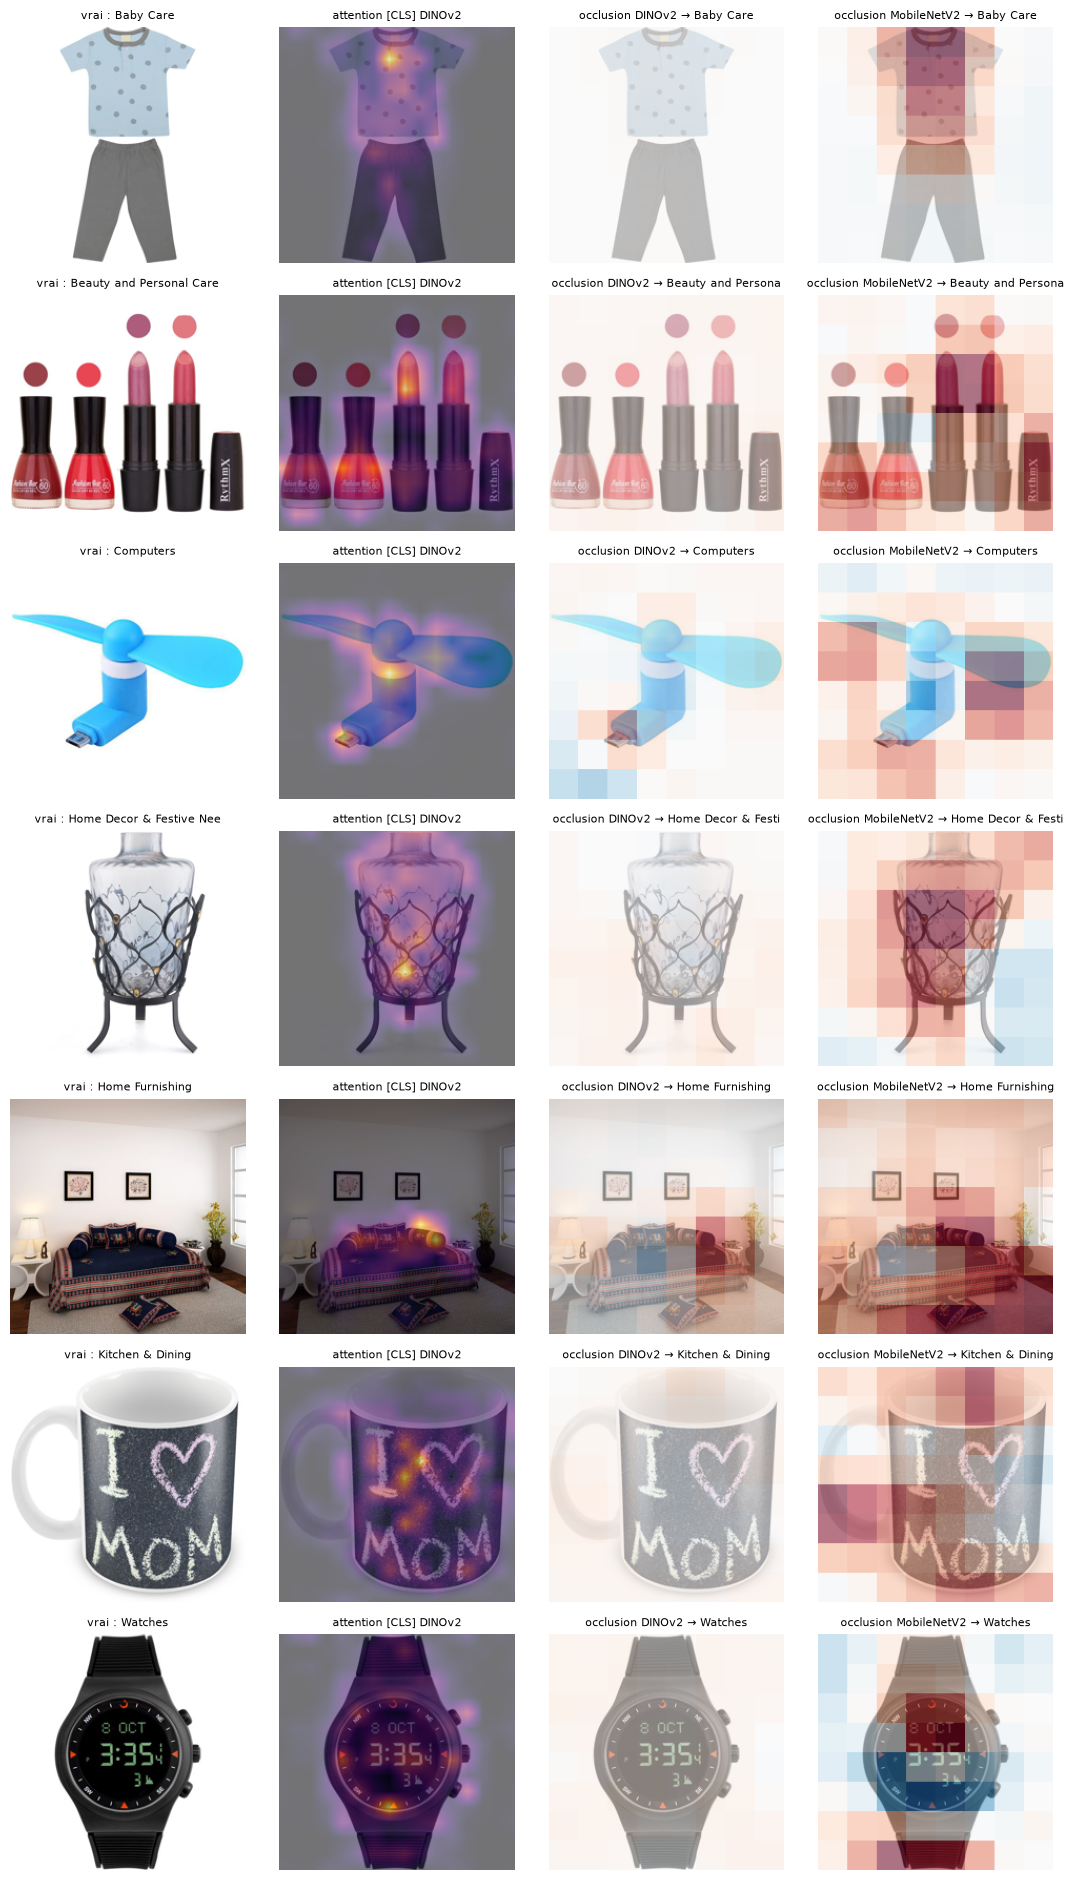

In [22]:
from scipy.ndimage import zoom


def superposer(ax, image, carte, cmap, vmin=None, vmax=None):
    ax.imshow(image)
    ax.imshow(zoom(carte, TAILLE / carte.shape[0], order=1), cmap=cmap, alpha=0.55, vmin=vmin, vmax=vmax)
    ax.axis("off")


exemples = [int(np.where(y == k)[0][3]) for k in range(len(CATEGORIES))]
fig, axes = plt.subplots(len(exemples), 4, figsize=(11, 2.7 * len(exemples)))
for ligne, i in zip(axes, exemples):
    image = carre_blanc(Image.open(df["chemin_image"].iloc[i]))
    tenseur = tenseurs[i]
    classe_dino = int(probabilites_dinov2(tenseur[None]).argmax())
    classe_mobile = int(probabilites_mobilenet(tenseur[None]).argmax())
    occ_dino = carte_occlusion(tenseur, probabilites_dinov2, classe_dino)
    occ_mobile = carte_occlusion(tenseur, probabilites_mobilenet, classe_mobile)
    borne = max(np.abs(occ_dino).max(), np.abs(occ_mobile).max(), 1e-6)
    ligne[0].imshow(image); ligne[0].axis("off")
    ligne[0].set_title(f"vrai : {CATEGORIES[y[i]][:24]}", fontsize=8)
    superposer(ligne[1], image, carte_attention(tenseur), "inferno")
    ligne[1].set_title("attention [CLS] DINOv2", fontsize=8)
    superposer(ligne[2], image, occ_dino, "RdBu_r", -borne, borne)
    ligne[2].set_title(f"occlusion DINOv2 → {CATEGORIES[classe_dino][:18]}", fontsize=8)
    superposer(ligne[3], image, occ_mobile, "RdBu_r", -borne, borne)
    ligne[3].set_title(f"occlusion MobileNetV2 → {CATEGORIES[classe_mobile][:18]}", fontsize=8)
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "importance_locale.png", dpi=110)
plt.show()

### Importance globale : où regarde le modèle, catégorie par catégorie ?

On moyenne les cartes d'attention de **toutes** les images de chaque catégorie, et on mesure la part de
l'attention qui tombe **sur le produit** plutôt que sur le fond blanc. Pour repérer le produit sans
annotation, on considère comme « fond » les pixels quasi blancs (les trois couleurs au-dessus de 240 sur
255).

In [23]:
@torch.no_grad()
def attentions_lot(lot):
    """Attention du [CLS] vers les patchs (dernière couche), normalisée pour sommer à 1 par image."""
    sortie = dinov2(pixel_values=lot, output_attentions=True)
    attention = sortie.attentions[-1][:, :, 0, DEBUT_PATCHS:].mean(dim=1)
    del sortie                      # libère tout de suite les attentions des 12 couches
    cote = int(attention.shape[1] ** 0.5)
    attention = attention.reshape(-1, cote, cote)
    return (attention / attention.sum(dim=(1, 2), keepdim=True)).numpy()


def patchs_produit(lot, cote_grille=16, seuil_blanc=240):
    """Vrai pour les patchs qui montrent le produit : moins de 90 % de pixels quasi blancs."""
    pixels = (lot.numpy().transpose(0, 2, 3, 1) * ECART_TYPE_IMAGENET + MOYENNE_IMAGENET) * 255
    blanc = (pixels > seuil_blanc).all(axis=3)                       # (lot, 224, 224)
    cote_patch = TAILLE // cote_grille                               # 14 pixels
    part_blanc = blanc.reshape(len(lot), cote_grille, cote_patch, cote_grille, cote_patch).mean(axis=(2, 4))
    return part_blanc < 0.9


# Piège rencontré à la première exécution : avec des lots de 32 images, cette cellule a pris
# 34 minutes au lieu des 5 attendues. Mesure faite sur 32 images : demander les attentions
# (output_attentions=True) renvoie celles des 12 couches, soit 1,2 Go par lot, et le processus
# monte à 2,5 Go alors que la machine n'avait que 2,2 Go de libres. Windows écrit alors sur le
# disque et tout ralentit. Avec des lots de 8, chaque lot ne pèse plus que 0,3 Go.
# Pour la même raison, le masque « produit » est calculé lot par lot, et non sur les 1 050
# images d'un coup (630 Mo de plus, sans compter les copies intermédiaires).
TAILLE_LOT_ATTENTION = 8
morceaux_attention, morceaux_produit = [], []
for i in range(0, len(y), TAILLE_LOT_ATTENTION):
    lot = tenseurs[i:i + TAILLE_LOT_ATTENTION]
    morceaux_attention.append(attentions_lot(lot))
    morceaux_produit.append(patchs_produit(lot))
toutes_attentions = np.concatenate(morceaux_attention)
produit = np.concatenate(morceaux_produit)

attention_sur_produit = (toutes_attentions * produit).sum(axis=(1, 2))
surface_produit = produit.mean(axis=(1, 2))
globale = pd.DataFrame({
    "surface occupée par le produit": surface_produit,
    "part de l'attention sur le produit": attention_sur_produit,
    "catégorie": df["categorie"],
}).groupby("catégorie").mean()
globale["concentration (attention / surface)"] = (globale.iloc[:, 1] / globale.iloc[:, 0]).round(2)
print(f"Sur l'ensemble des images : {surface_produit.mean():.0%} de la surface est occupée par le produit, "
      f"qui reçoit {attention_sur_produit.mean():.0%} de l'attention.")
globale.round(3)

Sur l'ensemble des images : 54% de la surface est occupée par le produit, qui reçoit 89% de l'attention.


,surface occupée par le produit,part de l'attention sur le produit,concentration (attention / surface)
catégorie,,,
Baby Care,0.599,0.904,1.51
Beauty and Personal Care,0.556,0.904,1.63
Computers,0.446,0.848,1.90
Home Decor & Festive Needs,0.549,0.901,1.64
Home Furnishing,0.686,0.929,1.35
Kitchen & Dining,0.536,0.883,1.65
Watches,0.411,0.847,2.06


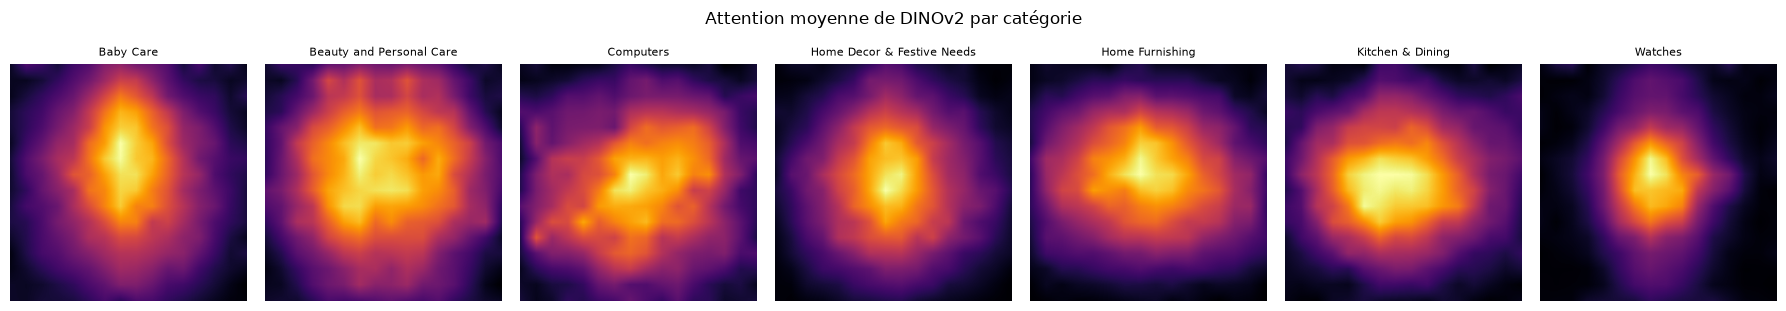

In [24]:
fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(18, 3))
for ax, (k, categorie) in zip(axes, enumerate(CATEGORIES)):
    moyenne = toutes_attentions[y == k].mean(axis=0)
    ax.imshow(zoom(moyenne, TAILLE / moyenne.shape[0], order=1), cmap="inferno")
    ax.set_title(categorie, fontsize=8); ax.axis("off")
plt.suptitle("Attention moyenne de DINOv2 par catégorie", y=1.02)
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "importance_globale_attention.png", dpi=120, bbox_inches="tight")
plt.show()

### Pourquoi la variante avec registres : la mesure

On compare l'attention de DINOv2 sans registres (la version d'origine) et avec registres, sur les mêmes
42 images (les 6 premières de chaque catégorie). Trois indicateurs :

- la part de l'attention qui tombe sur le produit, à comparer avec la surface qu'il occupe ;
- la part captée par le seul patch du coin en haut à gauche, un patch de fond sur 256 ;
- la part captée par les 5 patchs les plus regardés : si elle est forte, l'attention est accaparée par
  quelques points au lieu d'être répartie sur l'objet.

In [25]:
echantillon_reg = np.concatenate([np.where(y == k)[0][:6] for k in range(len(CATEGORIES))])
lot_reg = tenseurs[echantillon_reg]
produit_reg = patchs_produit(lot_reg)

comparaison_registres = []
for nom_hf in ("facebook/dinov2-base", NOM_HF):
    modele = AutoModel.from_pretrained(nom_hf, attn_implementation="eager").eval()
    # La version sans registres n'a pas ce réglage dans sa configuration : on compte alors 0 registre
    nb_registres = getattr(modele.config, "num_register_tokens", 0)
    debut = 1 + nb_registres                                 # premier patch : après [CLS] et les registres
    morceaux = []
    with torch.no_grad():
        for i in range(0, len(lot_reg), TAILLE_LOT_ATTENTION):
            sortie = modele(pixel_values=lot_reg[i:i + TAILLE_LOT_ATTENTION], output_attentions=True)
            morceaux.append(sortie.attentions[-1][:, :, 0, debut:].mean(dim=1))
            del sortie
    att = torch.cat(morceaux).reshape(-1, 16, 16).numpy()
    att = att / att.sum(axis=(1, 2), keepdims=True)
    comparaison_registres.append({
        "modèle": nom_hf,
        "registres": nb_registres,
        "surface du produit": produit_reg.mean(),
        "attention sur le produit": (att * produit_reg).sum(axis=(1, 2)).mean(),
        "attention sur le coin haut-gauche": att[:, 0, 0].mean(),
        "attention sur les 5 patchs les plus regardés": np.sort(att.reshape(len(att), -1), axis=1)[:, -5:].sum(axis=1).mean(),
    })
    del modele
pd.DataFrame(comparaison_registres).set_index("modèle").style.format(
    {c: "{:.1%}" for c in ["surface du produit", "attention sur le produit", "attention sur le coin haut-gauche",
                           "attention sur les 5 patchs les plus regardés"]})

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/224 [00:00<?, ?it/s]

,registres,surface du produit,attention sur le produit,attention sur le coin haut-gauche,attention sur les 5 patchs les plus regardés
modèle,,,,,
facebook/dinov2-base,0,53.0%,63.7%,15.1%,31.3%
facebook/dinov2-with-registers-base,4,53.0%,88.9%,0.1%,13.1%


### Importance globale par occlusion : quelles zones comptent, en moyenne ?

On répète l'occlusion sur 5 images par catégorie (35 images) et on moyenne les cartes, pour DINOv2 et
pour la baseline. On obtient, pour chaque modèle, l'importance moyenne de chaque zone de l'image dans la
décision. L'occlusion coûte 50 passages dans le réseau par image : 5 images par catégorie gardent la
cellule à une dizaine de minutes sur un processeur (durée affichée par la cellule ci-dessous).

Occlusion de 35 images pour 2 modèles : 4019 s


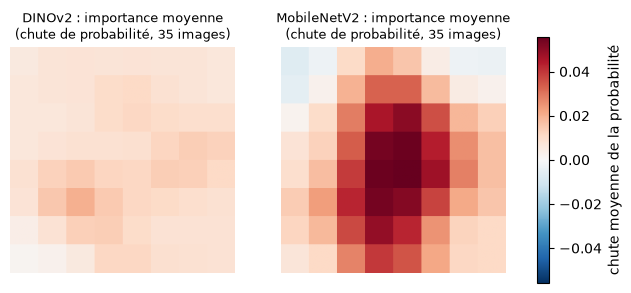

DINOv2       importance moyenne au centre 0.0116 | sur les bords 0.0086
MobileNetV2  importance moyenne au centre 0.0456 | sur les bords 0.0160


In [26]:
IMAGES_PAR_CATEGORIE = 5
echantillon = np.concatenate([np.where(y == k)[0][:IMAGES_PAR_CATEGORIE] for k in range(len(CATEGORIES))])
cartes = {"DINOv2": [], "MobileNetV2": []}
debut = time.perf_counter()
for i in echantillon:
    for nom, fonction in (("DINOv2", probabilites_dinov2), ("MobileNetV2", probabilites_mobilenet)):
        classe = int(fonction(tenseurs[i][None]).argmax())
        cartes[nom].append(carte_occlusion(tenseurs[i], fonction, classe))
print(f"Occlusion de {len(echantillon)} images pour 2 modèles : {time.perf_counter() - debut:.0f} s")
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
borne = max(np.abs(np.mean(c, axis=0)).max() for c in cartes.values())
for ax, (nom, liste) in zip(axes, cartes.items()):
    im = ax.imshow(np.mean(liste, axis=0), cmap="RdBu_r", vmin=-borne, vmax=borne)
    ax.set_title(f"{nom} : importance moyenne\n(chute de probabilité, {len(liste)} images)", fontsize=9)
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8, label="chute moyenne de la probabilité")
plt.savefig(DOSSIER_FIGURES / "importance_globale_occlusion.png", dpi=130, bbox_inches="tight")
plt.show()
for nom, liste in cartes.items():
    moyenne = np.mean(liste, axis=0)
    centre = moyenne[56:168, 56:168].mean(); bord = (moyenne.sum() - moyenne[56:168, 56:168].sum()) / (TAILLE**2 - 112**2)
    print(f"{nom:<12} importance moyenne au centre {centre:.4f} | sur les bords {bord:.4f}")

## 7. L'export du modèle final pour le dashboard

Le dashboard télécharge DINOv2 et MobileNetV2 depuis leurs sources publiques ; il n'a besoin que des
**classifieurs entraînés** (quelques centaines de kilo-octets) et de quelques informations pour
reproduire exactement la même préparation. On exporte aussi les prédictions hors pli, pour que le
dashboard affiche les performances mesurées ici sans rien recalculer.

In [27]:
import joblib

joblib.dump(classifieur_final, DOSSIER_MODELE / "classifieur_dinov2.joblib")
joblib.dump(classifieur_base, DOSSIER_MODELE / "classifieur_mobilenetv2.joblib")
configuration = {
    "categories": CATEGORIES,
    "nouveau_modele": {"nom": MEILLEUR, "hugging_face": NOM_HF, "C": C_FINAL},
    "baseline": {"nom": BASELINE, "torchvision": "mobilenet_v2 / IMAGENET1K_V1", "C": C_BASE},
    "preparation": {"taille": TAILLE, "fond": "blanc", "moyenne": MOYENNE_IMAGENET.tolist(),
                    "ecart_type": ECART_TYPE_IMAGENET.tolist()},
    "scores_validation_croisee": {n: round(float(tableau.loc[n, "exactitude"]), 4) for n in resultats},
    # Chiffres de la section 6, relus par le dashboard plutôt que recopiés à la main
    "interpretabilite": {"surface_produit": round(float(surface_produit.mean()), 3),
                         "attention_sur_produit": round(float(attention_sur_produit.mean()), 3)},
    # Les autres chiffres cités dans la note et la présentation, pour qu'aucun ne soit recopié à la main
    "doublons": {"paires": int(len(paires)),
                 "paires_categories_differentes": int(sum(df["categorie"].iloc[i] != df["categorie"].iloc[j]
                                                          for i, j in paires)),
                 "groupes": int(len(np.unique(groupes)))},
    "continuite_projet6": {n: round(float(v), 4) for n, v in continuite.items()},
    "registres": [{k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in ligne.items()}
                  for ligne in comparaison_registres],
    "c_choisis": {n: resultats[n]["c_choisis"] for n in resultats},
    "scores_plis": {n: [round(float(s), 4) for s in resultats[n]["scores_plis"]] for n in resultats},
}
(DOSSIER_MODELE / "configuration.json").write_text(json.dumps(configuration, indent=2, ensure_ascii=False),
                                                   encoding="utf-8")

# Données légères pour le dashboard : les métadonnées et les prédictions hors pli
dashboard_df = df[["image", "product_name", "categorie", "largeur", "hauteur"]].copy()
for nom in (BASELINE, MEILLEUR):
    dashboard_df[f"prediction {nom}"] = [CATEGORIES[k] for k in resultats[nom]["predictions"]]
    dashboard_df[f"confiance {nom}"] = resultats[nom]["probabilites"].max(axis=1).round(4)
dashboard_df.to_csv(DOSSIER_MODELE / "predictions_hors_pli.csv", index=False)
tableau.to_csv(DOSSIER_MODELE / "tableau_resultats.csv")
comparaisons.to_csv(DOSSIER_MODELE / "tests_mcnemar.csv")

# Contrôle : 5 images de référence et leurs représentations, pour vérifier que le dashboard prépare
# les images exactement comme ce notebook
np.save(DOSSIER_MODELE / "controle_representations.npy", representations[MEILLEUR][:5])
print(sorted(p.name for p in DOSSIER_MODELE.iterdir()))

['classifieur_dinov2.joblib', 'classifieur_mobilenetv2.joblib', 'configuration.json', 'controle_representations.npy', 'predictions_hors_pli.csv', 'tableau_resultats.csv', 'tests_mcnemar.csv']


## 8. Conclusion

La conclusion chiffrée est rédigée dans la note méthodologique (livrable 3), à partir des tableaux
ci-dessus. En résumé, ce notebook établit :

- le score de chaque représentation, à protocole identique et en validation croisée imbriquée ;
- la significativité de l'écart entre la baseline et DINOv2 (McNemar, image par image) ;
- l'écart à taille de modèle comparable (ResNet50 contre DINOv2-reg ViT-S/14), et s'il est ou non
  distinguable du bruit avec 1 050 images ;
- le coût du gain : nombre de paramètres et temps de prédiction ;
- où le modèle regarde, image par image et en moyenne par catégorie.